## 1. Environment Setup
First, let's install the official Ultralytics library along with OpenCV and Matplotlib, and verify our PyTorch configuration to ensure training uses GPU acceleration.

In [1]:
# Install the required packages
!pip install -q ultralytics opencv-python matplotlib pyyaml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 137.6 kB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 34.0 MB/s eta 0:00:0000:01


In [2]:
import torch
import ultralytics

# Verify ultralytics installation and GPU availability
ultralytics.checks()

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA (GPU) available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Active GPU Device: {torch.cuda.get_device_name(0)}")
else:
    print("WARNING: GPU not available. Training on CPU will be extremely slow. Please enable GPU acceleration if possible (e.g., in Google Colab or local CUDA setup).")

Ultralytics 8.4.118 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Setup complete ✅ (4 CPUs, 31.3 GB RAM, 7035.6/8062.4 GB disk)
PyTorch version: 2.10.0+cu128
CUDA (GPU) available: True
Active GPU Device: Tesla T4


## 2. Dataset Configuration & Inspection
This notebook now trains YOLO11 as a one-class tomato leaf detector using the cleaned `PlantDoc` dataset. The dataset contains only class `0: Tomato leaf`, with images under `images/train`, `images/val` and labels under `labels/train`, `labels/val`.

In [3]:
import os
from pathlib import Path
import yaml

PROJECT_ROOT = Path.cwd()
local_dataset_root = PROJECT_ROOT / "PlantDoc"
kaggle_dataset_root = Path("/kaggle/input/datasets/vthanhdt/plant-leaf-tomato")
runtime_yaml_path = PROJECT_ROOT / "plantdoc_tomato_leaf.yaml"

if kaggle_dataset_root.exists():
    print("Running on Kaggle with uploaded PlantDoc tomato leaf dataset.")
    dataset_root = kaggle_dataset_root
    runtime_yaml_path = Path("/kaggle/working/plantdoc_tomato_leaf.yaml")

    # If Kaggle preserved the local folder name, use the nested PlantDoc folder.
    if not (dataset_root / "images" / "train").exists() and (dataset_root / "PlantDoc" / "images" / "train").exists():
        dataset_root = dataset_root / "PlantDoc"
else:
    print("Running in local environment.")
    dataset_root = local_dataset_root

if not dataset_root.exists():
    raise FileNotFoundError(f"Dataset root not found: {dataset_root}")

active_config = {
    "path": str(dataset_root.resolve()).replace("\\", "/"),
    "train": "images/train",
    "val": "images/val",
    "nc": 1,
    "names": ["Tomato leaf"],
}

for rel_path in (active_config["train"], active_config["val"], "labels/train", "labels/val"):
    full_path = dataset_root / rel_path
    if not full_path.exists():
        raise FileNotFoundError(f"Expected dataset path not found: {full_path}")

with open(runtime_yaml_path, "w", encoding="utf-8") as f:
    yaml.safe_dump(active_config, f, sort_keys=False)

data_yaml_path = runtime_yaml_path

print(f"-> Dataset root: {dataset_root}")
print(f"-> Created YOLO config: {data_yaml_path}")
print("\n=== Active YOLO Tomato Leaf Configuration ===")
print(yaml.dump(active_config, sort_keys=False))


Running on Kaggle with uploaded PlantDoc tomato leaf dataset.
-> Dataset root: /kaggle/input/datasets/vthanhdt/plant-leaf-tomato
-> Created YOLO config: /kaggle/working/plantdoc_tomato_leaf.yaml

=== Active YOLO Tomato Leaf Configuration ===
path: /kaggle/input/datasets/vthanhdt/plant-leaf-tomato
train: images/train
val: images/val
nc: 1
names:
- Tomato leaf



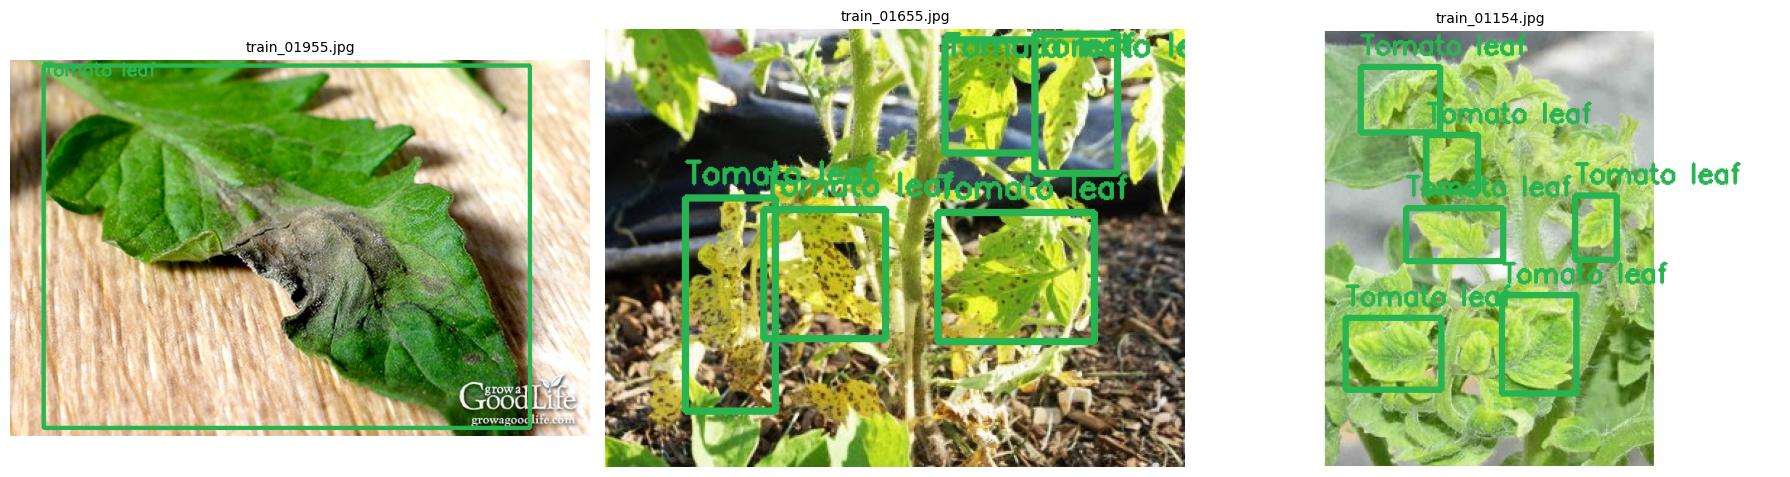

In [4]:
import cv2
import random
import matplotlib.pyplot as plt

CLASS_NAME = "Tomato leaf"

def split_dirs(split="train"):
    img_dir = Path(dataset_root) / "images" / split
    lbl_dir = Path(dataset_root) / "labels" / split
    return img_dir, lbl_dir

def visualize_dataset_samples(split="train", num_samples=3):
    img_dir, lbl_dir = split_dirs(split)

    if not img_dir.exists():
        print(f"Directory {img_dir} does not exist.")
        return

    image_files = [p for p in img_dir.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
    if not image_files:
        print(f"No images found in {img_dir}")
        return

    selected_images = random.sample(image_files, min(num_samples, len(image_files)))
    fig, axes = plt.subplots(1, len(selected_images), figsize=(18, 6))

    if len(selected_images) == 1:
        axes = [axes]

    for ax, img_path in zip(axes, selected_images):
        lbl_path = lbl_dir / f"{img_path.stem}.txt"

        img = cv2.imread(str(img_path))
        if img is None:
            ax.set_title(f"Could not read {img_path.name}", fontsize=10)
            ax.axis("off")
            continue

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w, _ = img.shape

        if lbl_path.exists():
            with open(lbl_path, "r", encoding="utf-8") as f:
                lines = f.readlines()

            for line in lines:
                parts = line.strip().split()
                if len(parts) == 5 and parts[0] == "0":
                    x_c, y_c, bw, bh = map(float, parts[1:])
                    x1 = int((x_c - bw / 2.0) * w)
                    y1 = int((y_c - bh / 2.0) * h)
                    x2 = int((x_c + bw / 2.0) * w)
                    y2 = int((y_c + bh / 2.0) * h)

                    cv2.rectangle(img, (x1, y1), (x2, y2), (40, 180, 80), 3)
                    cv2.putText(img, CLASS_NAME, (x1, max(18, y1 - 10)),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (40, 180, 80), 2)

        ax.imshow(img)
        ax.set_title(img_path.name, fontsize=10)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

visualize_dataset_samples(split="train", num_samples=3)


## 3. Model Initialization
YOLO11 is the latest state-of-the-art iteration of YOLO by Ultralytics. It introduces architectural refinements such as C3k2 blocks and improved SPPF layers. We will initialize the **YOLO11s** (small) variant, which strikes an optimal balance between execution speed (ideal for real-time edge processing) and detection accuracy.

In [5]:
from ultralytics import YOLO

# Initialize YOLO11s model from COCO pretrained weights
model = YOLO("yolo11s.pt")

# Print class mapping for pretrained weights (should show COCO classes, e.g. 0: person)
print("Model classes in COCO:", list(model.names.values())[:5])

Model classes in COCO: ['person', 'bicycle', 'car', 'motorcycle', 'airplane']


## 4. Training (Fine-Tuning)
We train YOLO11 as a **one-class tomato leaf detector**. The cleaned `PlantDoc` labels all tomato leaf boxes as class `0: Tomato leaf`, so the detector learns where tomato leaves are before your separate `PlantVillage` classifier handles disease recognition.

Recommended settings:
- `epochs=150`: enough for the smaller cleaned PlantDoc dataset, with early stopping enabled.
- `imgsz=800`: preserves leaf-region detail for detection.
- `batch=16`: VRAM-friendly batch size; reduce to `8` or `4` if CUDA memory is limited.
- `optimizer='AdamW'`: stable for fine-tuning.
- `mosaic=0.5`, `mixup=0.0`, `copy_paste=0.0`: moderate augmentation for leaf boxes.
- `close_mosaic=20`: final epochs focus on real image geometry.
- `patience=40`: stops when validation stops improving.


In [6]:
# Start fine-tuning the pretrained YOLO11 detector for one class: Tomato leaf.
results = model.train(
    data=str(data_yaml_path),
    epochs=150,
    imgsz=800,
    batch=16,
    device=0,
    optimizer="AdamW",
    lr0=0.001,
    lrf=0.01,
    weight_decay=0.0005,
    warmup_epochs=3.0,
    mosaic=0.5,
    mixup=0.0,
    copy_paste=0.0,
    close_mosaic=20,
    patience=40,
    val=True,
    plots=True,
    project="tomato_leaf_detect",
    name="yolo11s_plantdoc_tomato_leaf"
)


Ultralytics 8.4.118 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=20, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/plantdoc_tomato_leaf.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=yolo11s_plantdoc_

## 5. Evaluation & Metrics Analysis
After training, let's load our trained best weights (`best.pt`) and evaluate its performance against the Validation set. YOLO automatically calculates mAP@50 and mAP@50-95 metrics.

In [7]:
# Load the best trained model weight from the run that was just trained.
best_model_path = os.path.join(str(results.save_dir), "weights", "best.pt")
best_model = YOLO(best_model_path)

    # Run validation evaluation on the active one-class tomato leaf dataset.
metrics = best_model.val(data=str(data_yaml_path))

print("\n=== Evaluation Metrics on PlantDoc Tomato Leaf Validation Set ===")
print(f"Precision (P):   {metrics.box.mp:.4f}")
print(f"Recall (R):      {metrics.box.mr:.4f}")
print(f"mAP @ 0.5:       {metrics.box.map50:.4f}")
print(f"mAP @ 0.5-0.95:  {metrics.box.map:.4f}")


Ultralytics 8.4.118 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 101 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 409.0±677.7 MB/s, size: 414.6 KB)
val: Scanning /kaggle/input/datasets/vthanhdt/plant-leaf-tomato/labels/val... 69 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 69/69 990.7it/s 0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/vthanhdt/plant-leaf-tomato/labels is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.9it/s 2.7s0.8s
                   all         69        192      0.793       0.75      0.828       0.53
Speed: 5.6ms preprocess, 14.1ms inference, 0.4ms loss, 6.9ms postprocess per image
Results saved to /kaggle/working/runs/detect/val

=== Evaluation Metrics on PlantDoc Tomato Leaf Validation Set ===
Precision (P):   0.7932
Recall (R):      0.7500
mAP @ 

### Plotting Training Results & Confusion Matrix
Display the generated training loss plots and confusion matrix for the tomato leaf detector.


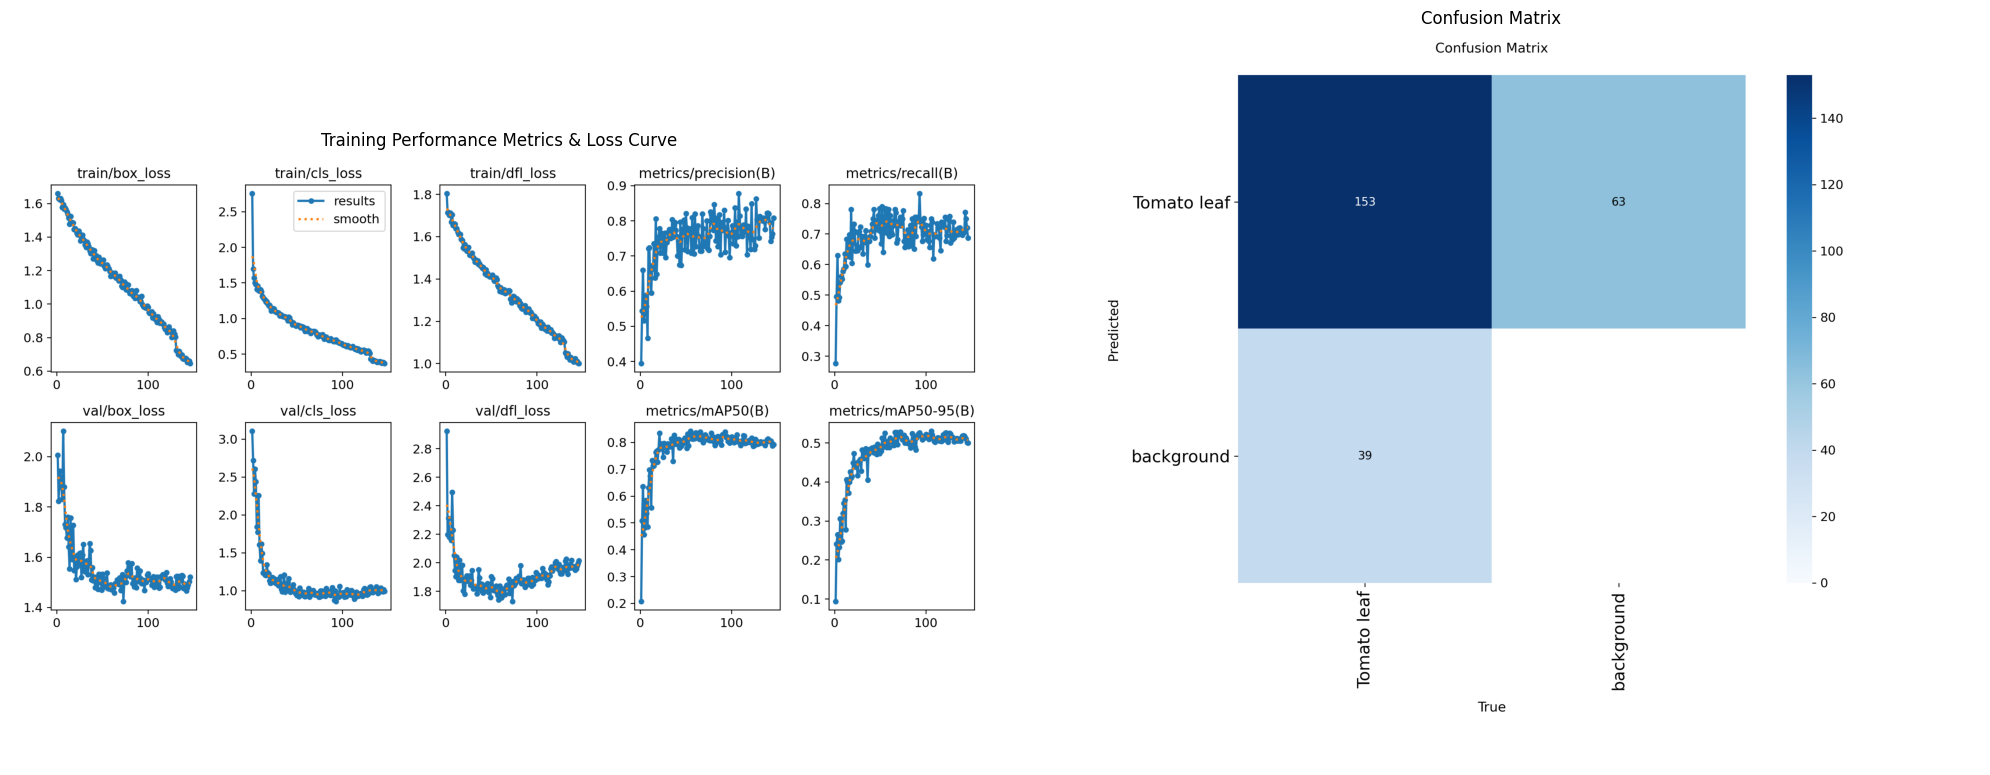

In [8]:
import matplotlib.image as mpimg

run_dir = str(results.save_dir)
results_png = os.path.join(run_dir, "results.png")
confusion_png = os.path.join(run_dir, "confusion_matrix.png")

fig, axes = plt.subplots(1, 2, figsize=(20, 10)) if os.path.exists(results_png) and os.path.exists(confusion_png) else plt.subplots(1, 1, figsize=(10, 10))

if os.path.exists(results_png):
    img1 = mpimg.imread(results_png)
    if isinstance(axes, list) or hasattr(axes, "__iter__"):
        axes[0].imshow(img1)
        axes[0].set_title("Training Performance Metrics & Loss Curve")
        axes[0].axis("off")
    else:
        axes.imshow(img1)
        axes.axis("off")

if os.path.exists(confusion_png) and (isinstance(axes, list) or hasattr(axes, "__iter__")):
    img2 = mpimg.imread(confusion_png)
    axes[1].imshow(img2)
    axes[1].set_title("Confusion Matrix")
    axes[1].axis("off")

plt.tight_layout()
plt.show()


## 6. Inference & Visual Quality Check
Run inference on validation images to visually confirm that the trained model detects tomato leaf regions.



image 1/1 /kaggle/input/datasets/vthanhdt/plant-leaf-tomato/images/val/val_00147.jpg: 640x800 4 Tomato leafs, 18.2ms
Speed: 3.5ms preprocess, 18.2ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 800)


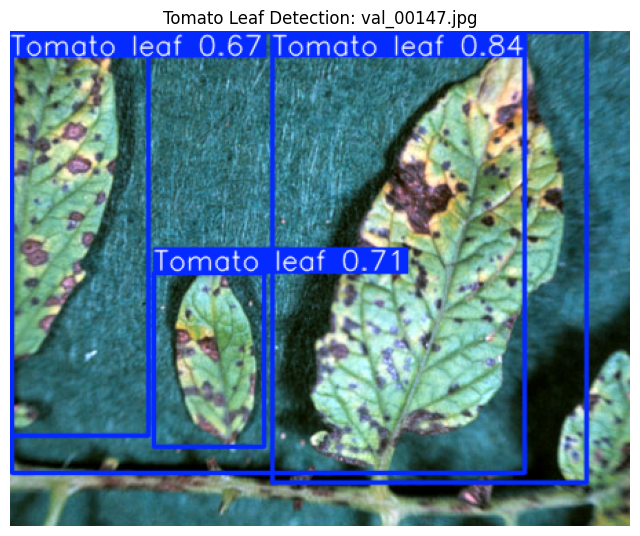


image 1/1 /kaggle/input/datasets/vthanhdt/plant-leaf-tomato/images/val/val_00205.jpg: 544x800 5 Tomato leafs, 56.0ms
Speed: 2.8ms preprocess, 56.0ms inference, 1.4ms postprocess per image at shape (1, 3, 544, 800)


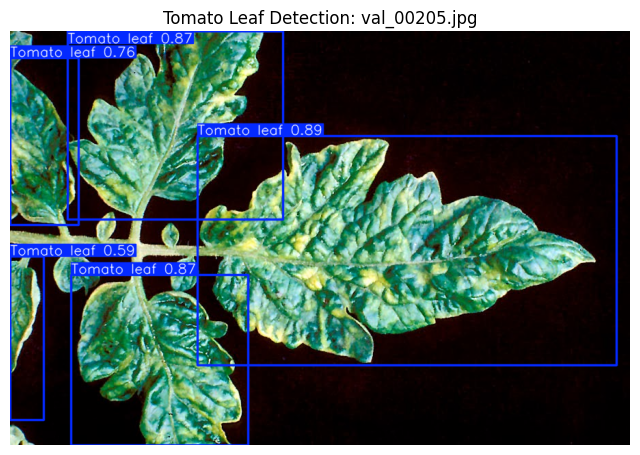


image 1/1 /kaggle/input/datasets/vthanhdt/plant-leaf-tomato/images/val/val_00088.jpg: 608x800 3 Tomato leafs, 55.6ms
Speed: 2.9ms preprocess, 55.6ms inference, 1.4ms postprocess per image at shape (1, 3, 608, 800)


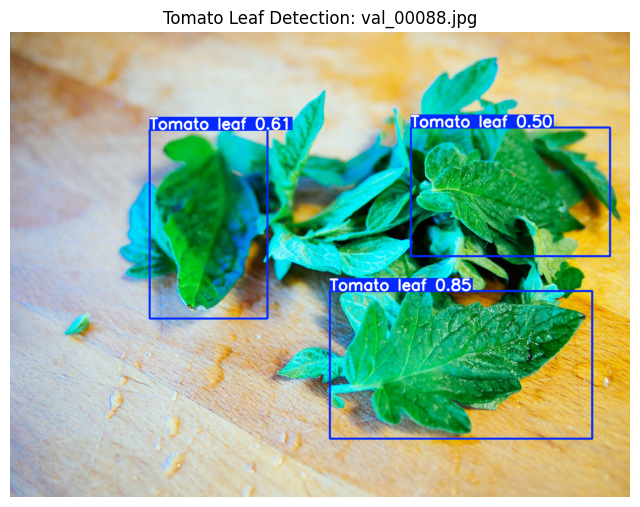


image 1/1 /kaggle/input/datasets/vthanhdt/plant-leaf-tomato/images/val/val_00115.jpg: 544x800 1 Tomato leaf, 17.2ms
Speed: 2.3ms preprocess, 17.2ms inference, 1.4ms postprocess per image at shape (1, 3, 544, 800)


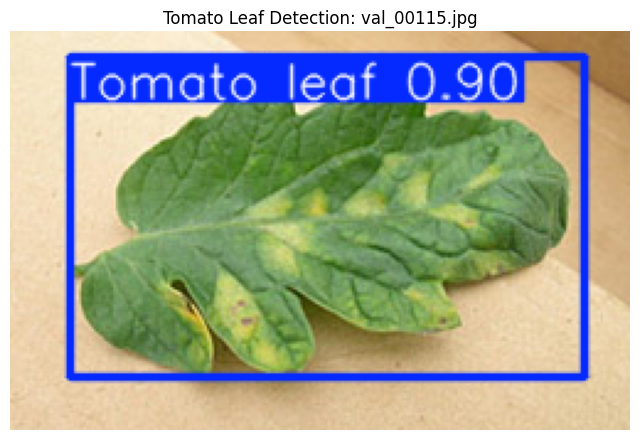

In [9]:
import glob

# PlantDoc currently has train/val splits. Use val images for a quick visual check.
inference_img_dir = Path(dataset_root) / "images" / "val"
inference_images = []
for ext in ("*.jpg", "*.jpeg", "*.png"):
    inference_images.extend(glob.glob(str(inference_img_dir / ext)))

if inference_images:
    selected_images = random.sample(inference_images, min(4, len(inference_images)))

    for img_path in selected_images:
        pred_res = best_model.predict(source=img_path, conf=0.35, iou=0.45)

        for r in pred_res:
            img_bgr = r.plot()
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

            plt.figure(figsize=(8, 8))
            plt.imshow(img_rgb)
            plt.title(f"Tomato Leaf Detection: {os.path.basename(img_path)}")
            plt.axis("off")
            plt.show()
else:
    print(f"No images found to run inference on at: {inference_img_dir}")


## 7. Model Export
Once training is complete, the PyTorch checkpoint (`best.pt`) is optimized for training. To deploy this model into production (e.g. mobile applications, edge devices, or web servers), exporting it to formats like **ONNX** or **TensorRT** is highly recommended. ONNX files provide high compatibility and runtime performance optimization.

In [10]:
# Export the best weights to ONNX format.
onnx_file = best_model.export(format="onnx")

print("\nSUCCESS: Tomato leaf detector exported to ONNX format!")
print(f"You can find the exported model here: {onnx_file}")


Ultralytics 8.4.118 🚀 Python-3.12.13 torch-2.10.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino/

PyTorch: starting from '/kaggle/working/runs/detect/tomato_leaf_detect/yolo11s_plantdoc_tomato_leaf/weights/best.pt' with input shape (1, 3, 800, 800) BCHW and output shape(s) (1, 5, 13125) (18.3 MB)
requirements: Ultralytics requirements ['onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 12 packages in 349ms
Prepared 2 packages in 304ms
Installed 2 packages in 13ms
 + onnxruntime==1.28.0
 + onnxslim==0.1.95

requirements: AutoUpdate success ✅ 1.0s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.22.0 opset 20...
ONNX: slimming with onnxslim 0.1.95...
ONNX: export success ✅ 3.5s, saved as '/kaggle/working/runs/detect/t